# 03 Exploratory Data Analysis
One chart per topic. Under each chart: what I see (observation) and what I think it means (interpretation).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/hotel_bookings_clean.csv", parse_dates=["arrival_date"])
FIG = "../reports/figures/"
BLUE, ORANGE, GREY = "#3B6EA8", "#E07B39", "#9AA0A6"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10})
OVERALL = df["is_canceled"].mean()
print(f"Overall cancellation rate: {OVERALL:.1%}")

def rate_bar(col, order=None, title="", xlabel="", fname=None, rotate=0, min_n=0):
    """Bar chart of cancellation rate per category, with the overall rate as a dashed line."""
    g = df.groupby(col, observed=True)["is_canceled"].agg(["mean", "size"])
    g = g[g["size"] >= min_n]
    if order is not None:
        g = g.reindex([o for o in order if o in g.index])
    fig, ax = plt.subplots(figsize=(7, 3.8))
    colors = [ORANGE if m > OVERALL else BLUE for m in g["mean"]]
    bars = ax.bar(g.index.astype(str), g["mean"] * 100, color=colors)
    ax.axhline(OVERALL * 100, ls="--", color=GREY, lw=1)
    ax.text(len(g) - 0.5, OVERALL * 100 + 1.5, f"overall {OVERALL:.0%}", ha="right", color="dimgray", fontsize=9)
    for b, (m, n) in zip(bars, g.values):
        ax.text(b.get_x() + b.get_width() / 2, m * 100 + 1, f"{m:.0%}", ha="center", fontsize=9)
    ax.set_ylabel("Cancellation rate (%)"); ax.set_xlabel(xlabel); ax.set_title(title)
    ax.set_ylim(0, max(100, g["mean"].max() * 110))
    plt.xticks(rotation=rotate)
    plt.tight_layout()
    if fname: plt.savefig(FIG + fname, bbox_inches="tight")
    plt.show()
    return g

Overall cancellation rate: 37.1%


## 1. Cancellation rate

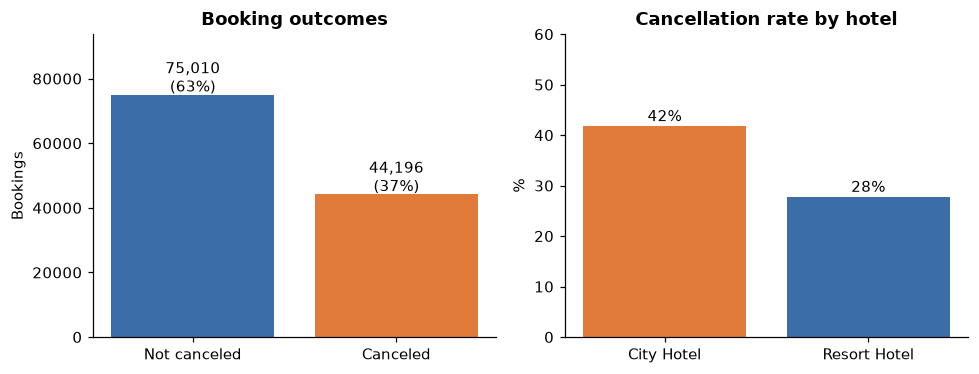

Canceled room-nights: 154,147  |  booked revenue that was canceled: €16.7M over 26 months


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
c = df["is_canceled"].value_counts().sort_index()
ax[0].bar(["Not canceled", "Canceled"], c.values, color=[BLUE, ORANGE])
for i, v in enumerate(c.values): ax[0].text(i, v + 1000, f"{v:,}\n({v/len(df):.0%})", ha="center")
ax[0].set_title("Booking outcomes"); ax[0].set_ylabel("Bookings"); ax[0].set_ylim(0, c.max() * 1.25)
h = df.groupby("hotel")["is_canceled"].mean() * 100
ax[1].bar(h.index, h.values, color=[ORANGE, BLUE])
for i, v in enumerate(h.values): ax[1].text(i, v + 1, f"{v:.0f}%", ha="center")
ax[1].set_title("Cancellation rate by hotel"); ax[1].set_ylabel("%"); ax[1].set_ylim(0, 60)
plt.tight_layout(); plt.savefig(FIG + "fig01_target_and_hotel.png", bbox_inches="tight"); plt.show()

lost_nights = (df.loc[df.is_canceled == 1, "total_nights"]).sum()
lost_rev = (df.loc[df.is_canceled == 1, "total_nights"] * df.loc[df.is_canceled == 1, "adr"]).sum()
print(f"Canceled room-nights: {lost_nights:,}  |  booked revenue that was canceled: €{lost_rev/1e6:.1f}M over 26 months")

Observation: 37% of bookings cancel, 42% at the City Hotel and 28% at the Resort.

Interpretation: this is a big and costly problem, and the two hotels behave differently, so `hotel` is a model feature.

## 2. Lead time

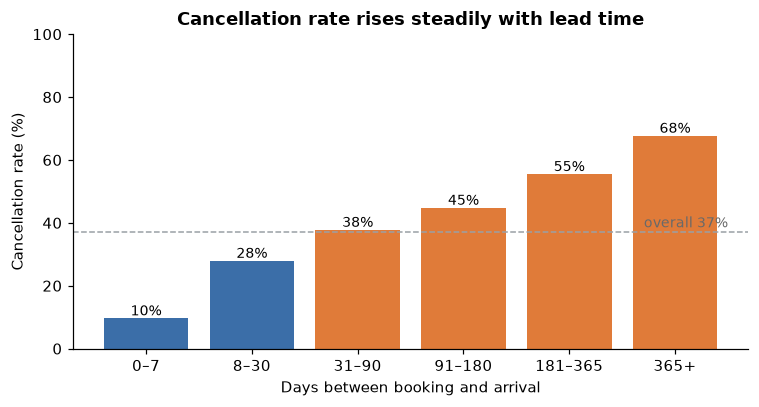

,mean,size
lead_bin,,
0–7,0.095910,19633
8–30,0.278860,18945
31–90,0.377269,29528
91–180,0.447350,26420
181–365,0.554591,21533
365+,0.676517,3147


In [3]:
bins = [-1, 7, 30, 90, 180, 365, 800]
labels = ["0–7", "8–30", "31–90", "91–180", "181–365", "365+"]
df["lead_bin"] = pd.cut(df["lead_time"], bins=bins, labels=labels)
rate_bar("lead_bin", labels, "Cancellation rate rises steadily with lead time",
         "Days between booking and arrival", "fig02_lead_time.png")

Observation: last-minute bookings (≤7 days) cancel about 10%. Bookings made more than a year ahead cancel about 68%.

Interpretation: more time before arrival means more time for plans to change or to find a better deal. Lead time is probably the strongest signal.

## 3. Deposit type

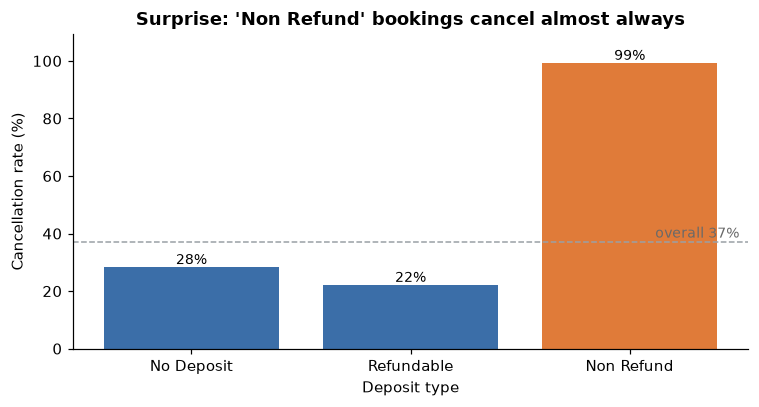

                  mean    size
deposit_type                  
No Deposit    0.284009  104458
Refundable    0.222222     162
Non Refund    0.993624   14586
               market_segment  country
Corporate                0.02      NaN
ESP                       NaN     0.01
GBR                       NaN     0.01
Groups                   0.63      NaN
Offline TA/TO            0.34      NaN
PRT                       NaN     0.97


In [4]:
g = rate_bar("deposit_type", ["No Deposit", "Refundable", "Non Refund"],
             "Surprise: 'Non Refund' bookings cancel almost always", "Deposit type", "fig03_deposit.png")
print(g)
print(df[df.deposit_type == "Non Refund"][["market_segment", "country"]].apply(lambda s: s.value_counts(normalize=True).head(3)).round(2))

Observation: 99% of Non Refund bookings are canceled. 97% of them are Portuguese, mostly Groups and Offline travel agents.

Interpretation: this doesn't mean deposits cause cancellations. More likely, agents block rooms for groups on a non-refundable rate and release the ones they can't sell. It's useful for prediction, but it's correlation, not causation, so I shouldn't tell the hotel to remove deposits.

## 4. Sales channel

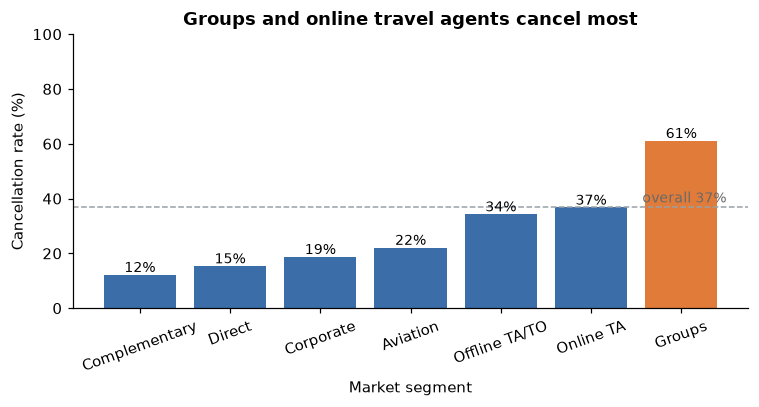

,mean,size
market_segment,,
Complementary,0.122253,728
Direct,0.153712,12582
Corporate,0.187618,5282
Aviation,0.221277,235
Offline TA/TO,0.343286,24181
Online TA,0.367590,56408
Groups,0.611117,19790


In [5]:
order = df.groupby("market_segment")["is_canceled"].mean().sort_values().index
rate_bar("market_segment", order, "Groups and online travel agents cancel most", "Market segment",
         "fig04_market_segment.png", rotate=20)

Observation: Groups (61%) and Online TA (37%) are above average. Direct (15%) and Corporate (19%) are much lower.

Interpretation: online platforms make free cancellation easy, so guests book now and decide later. Guests who book directly are more committed.

## 5. Season

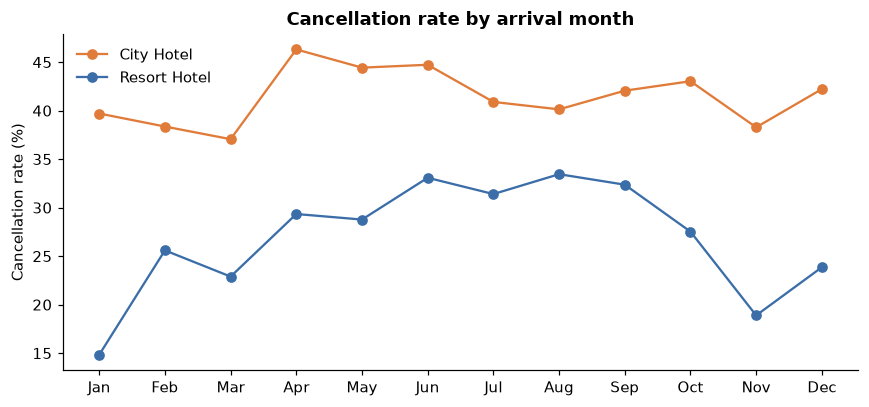

In [6]:
m = df.groupby(["arrival_month", "hotel"])["is_canceled"].mean().unstack() * 100
vol = df.groupby("arrival_month").size()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(m.index, m["City Hotel"], marker="o", color=ORANGE, label="City Hotel")
ax.plot(m.index, m["Resort Hotel"], marker="o", color=BLUE, label="Resort Hotel")
ax.set_xticks(range(1, 13), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_ylabel("Cancellation rate (%)"); ax.set_title("Cancellation rate by arrival month"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG + "fig05_seasonality.png", bbox_inches="tight"); plt.show()

Observation: at the Resort the cancel rate goes from about 15% in January to about 33% in summer. The City Hotel stays high all year (38–46%).

Interpretation: the Resort gets the most cancellations when demand is highest. An empty room hurts most then, but it's also easier to resell. Arrival month is a model feature.

## 6. Special requests

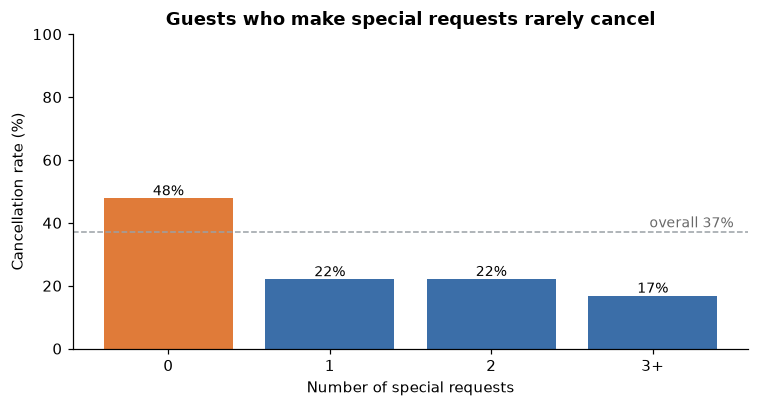

,mean,size
requests_capped,,
0,0.477685,70199
1,0.220451,33182
2,0.221218,12951
3+,0.168058,2874


In [7]:
df["requests_capped"] = df["total_of_special_requests"].clip(upper=3).astype(str).replace("3", "3+")
rate_bar("requests_capped", ["0", "1", "2", "3+"], "Guests who make special requests rarely cancel",
         "Number of special requests", "fig06_special_requests.png")

Observation: bookings with no special request cancel 48%. With one or more, about 20%.

Interpretation: a guest who asks for a high floor or a baby cot is really planning the trip.

## 7. Guest history

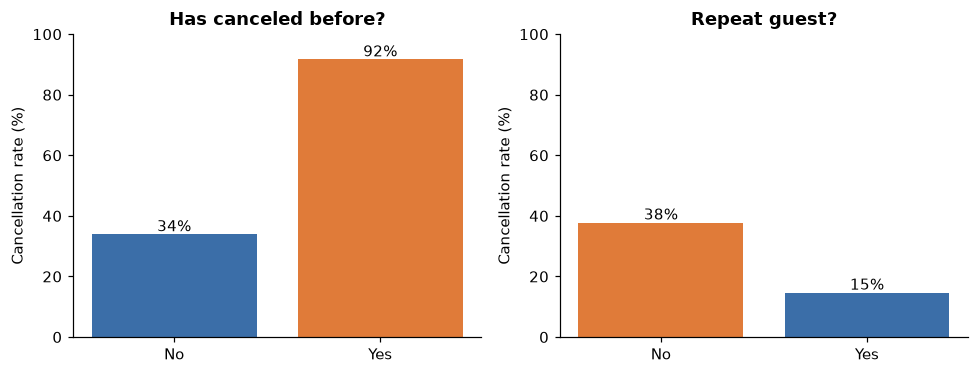

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
for a, col, lab in [(ax[0], "had_previous_cancel", ["No", "Yes"]), (ax[1], "is_repeated_guest", ["No", "Yes"])]:
    r = df.groupby(col)["is_canceled"].mean() * 100
    a.bar(lab, r.values, color=[BLUE, ORANGE] if r.iloc[1] > r.iloc[0] else [ORANGE, BLUE])
    for i, v in enumerate(r.values): a.text(i, v + 1, f"{v:.0f}%", ha="center")
    a.set_ylim(0, 100); a.set_ylabel("Cancellation rate (%)")
ax[0].set_title("Has canceled before?"); ax[1].set_title("Repeat guest?")
plt.tight_layout(); plt.savefig(FIG + "fig07_history.png", bbox_inches="tight"); plt.show()

Observation: guests who canceled before cancel 92% of the time. Repeat guests cancel 15%.

Interpretation: past behaviour predicts future behaviour. Loyal guests are low risk.

## 8. Price

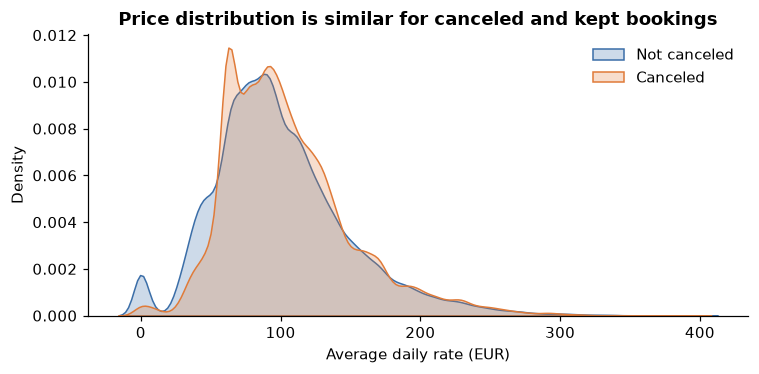

is_canceled
0    92.7
1    96.3
Name: adr, dtype: float64


In [9]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for flag, color, label in [(0, BLUE, "Not canceled"), (1, ORANGE, "Canceled")]:
    sns.kdeplot(df.loc[(df.adr < 400) & (df.is_canceled == flag), "adr"], fill=True, color=color, label=label, ax=ax)
ax.legend(frameon=False)
ax.set_xlabel("Average daily rate (EUR)"); ax.set_title("Price distribution is similar for canceled and kept bookings")
plt.tight_layout(); plt.savefig(FIG + "fig08_adr.png", bbox_inches="tight"); plt.show()
print(df.groupby("is_canceled")["adr"].median())

Observation: prices of canceled and kept bookings overlap a lot (median €96 vs €93).

Interpretation: price alone is a weak signal. It may still help together with season and hotel.

## 9. Country

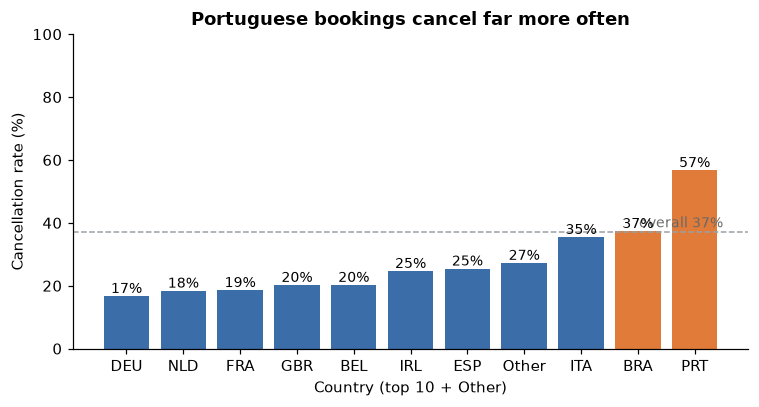

,mean,size
country_group,,
DEU,0.167193,7285
NLD,0.184023,2103
FRA,0.185848,10401
GBR,0.202327,12119
BEL,0.202391,2342
IRL,0.246592,3374
ESP,0.254322,8560
Other,0.272482,18559
ITA,0.354427,3761


In [10]:
order = df.groupby("country_group")["is_canceled"].mean().sort_values().index
rate_bar("country_group", order, "Portuguese bookings cancel far more often", "Country (top 10 + Other)",
         "fig09_country.png", rotate=0)

Observation: bookings from Portugal cancel about 57%. Most foreign countries are 15–25%.

Interpretation: domestic guests can cancel cheaply (no flights), and most group and Non Refund blocks are domestic.

Caution: country may only be corrected at check-in, so canceled bookings may keep the default "PRT". In notebook 04 I test the model without country.

## 10. Correlations

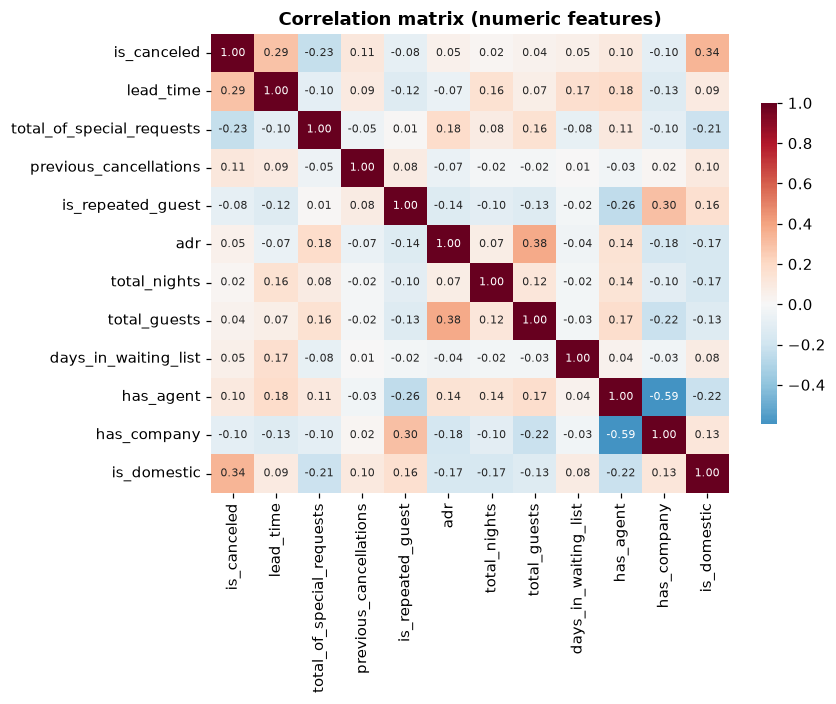

total_of_special_requests   -0.234909
has_company                 -0.099688
is_repeated_guest           -0.083717
total_nights                 0.018599
total_guests                 0.044811
adr                          0.047629
days_in_waiting_list         0.054306
has_agent                    0.102279
previous_cancellations       0.110145
lead_time                    0.292920
is_domestic                  0.336913
Name: is_canceled, dtype: float64

In [11]:
num = ["is_canceled", "lead_time", "total_of_special_requests", "previous_cancellations", "is_repeated_guest",
       "adr", "total_nights", "total_guests", "days_in_waiting_list", "has_agent", "has_company", "is_domestic"]
corr = df[num].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax, cbar_kws={"shrink": .7})
ax.set_title("Correlation matrix (numeric features)")
plt.tight_layout(); plt.savefig(FIG + "fig10_correlation.png", bbox_inches="tight"); plt.show()
corr["is_canceled"].drop("is_canceled").sort_values()

Observation: the strongest links with cancellation are `is_domestic` (+), `lead_time` (+) and special requests (−). No two features are so correlated that it would cause problems.

## Summary
1. Longer lead time, higher risk.
2. Groups and Online TA are high risk, Direct and Corporate low.
3. Non Refund and domestic bookings are high risk (probably group blocks, not causation).
4. Special requests and repeat guests mean lower risk.
5. Previous cancellations mean higher risk.

These patterns are strong, so a model should beat the baseline easily.